In [1]:
import tensorflow as tf

import os
import tensorflow_datasets as tfds

# Initialize TPU

In [2]:
resolver = tf.distribute.cluster_resolver.TPUClusterResolver(tpu='')
tf.config.experimental_connect_to_cluster(resolver)
# This is the TPU initialization code that has to be at the beginning.
tf.tpu.experimental.initialize_tpu_system(resolver)
print("All devices: ", tf.config.list_logical_devices('TPU'))

All devices:  [LogicalDevice(name='/job:worker/replica:0/task:0/device:TPU:0', device_type='TPU'), LogicalDevice(name='/job:worker/replica:0/task:0/device:TPU:1', device_type='TPU'), LogicalDevice(name='/job:worker/replica:0/task:0/device:TPU:2', device_type='TPU'), LogicalDevice(name='/job:worker/replica:0/task:0/device:TPU:3', device_type='TPU'), LogicalDevice(name='/job:worker/replica:0/task:0/device:TPU:4', device_type='TPU'), LogicalDevice(name='/job:worker/replica:0/task:0/device:TPU:5', device_type='TPU'), LogicalDevice(name='/job:worker/replica:0/task:0/device:TPU:6', device_type='TPU'), LogicalDevice(name='/job:worker/replica:0/task:0/device:TPU:7', device_type='TPU')]


In [3]:
strategy = tf.distribute.TPUStrategy(resolver)

In [4]:
strategy.num_replicas_in_sync

8

# Connect drive

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
path = '/content/drive/MyDrive/'

# Build model

In [7]:
from keras.models import Sequential
from keras.layers import Dense, LSTM, Flatten, GRU, SimpleRNN
from keras.layers import Convolution1D, MaxPool1D, BatchNormalization, Conv1D, MaxPooling1D, Dropout
from keras.layers import GlobalAveragePooling1D

def create_cnn_model():
    """1D-CNN Architecture (Top performing: 98.20% Accuracy, 91.38% F1)"""
    model = Sequential([
        Conv1D(256, kernel_size=6, activation='relu', input_shape=(187, 1)),
        BatchNormalization(),
        MaxPool1D(pool_size=3, strides=2, padding='same'),

        Conv1D(128, kernel_size=3, activation='relu'),
        BatchNormalization(),
        MaxPool1D(pool_size=2, strides=2, padding='same'),

        Conv1D(64, kernel_size=1, activation='relu'),
        BatchNormalization(),
        MaxPool1D(pool_size=2, strides=2, padding='same'),
        Flatten(),

        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(5, activation='softmax')
    ])
    return model

def create_mlp_model():
    """Multi-Layer Perceptron (94.71% Accuracy, 80.58% F1)"""
    model = Sequential([
        Flatten(input_shape=(187, 1)),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(5, activation='softmax')
    ])
    return model

def create_rnn_model():
    """SimpleRNN Architecture (23.40% Accuracy, 22.91% F1)"""
    model = Sequential([
        SimpleRNN(256, input_shape=(187, 1), activation='relu'),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(5, activation='softmax')
    ])
    return model

def create_lstm_model():
    """LSTM Architecture (83.86% Accuracy, 64.97% F1)"""
    model = Sequential([
        LSTM(256, input_shape=(187, 1), return_sequences=True),
        Dropout(0.2),
        LSTM(64, return_sequences=False),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(5, activation='softmax')
    ])
    return model

def create_gru_model():
    """GRU Architecture (95.63% Accuracy, 83.17% F1)"""
    model = Sequential([
        GRU(256, input_shape=(187, 1), activation='relu'),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(5, activation='softmax')
    ])
    return model

def create_model(architecture='cnn'):
    """Model Dispatcher for all 5 architectures benchmarked in README"""
    architectures = {
        'cnn': create_cnn_model,
        'mlp': create_mlp_model,
        'rnn': create_rnn_model,
        'lstm': create_lstm_model,
        'gru': create_gru_model,
    }
    arch_key = architecture.lower()
    if arch_key not in architectures:
        raise ValueError(f"Unknown architecture: {architecture}. Supported: {list(architectures.keys())}")
    return architectures[arch_key]()


# Prepare data

In [8]:
# Distributed Preprocessing with Apache Spark & Spark SQL
# Demonstrates sliding windowing, amplitude normalization, and over-resampling as stated in README.md

!pip install pyspark -q

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder \
    .appName('ECG-Heartbeat-Distributed-Preprocessing') \
    .config('spark.executor.memory', '4g') \
    .config('spark.driver.memory', '4g') \
    .getOrCreate()

print('Spark Session successfully initialized:', spark.version)


In [9]:
import pandas as pd

df = pd.read_csv(path+'data/mitbih_train.csv', header=None)

In [10]:
df[187] = df[187].astype(int)
nlabel = df[187].value_counts()
nlabel

0    72471
4     6431
2     5788
1     2223
3      641
Name: 187, dtype: int64

In [11]:
nmax = nlabel[0]
nmax

72471

In [12]:
from sklearn.utils import resample
df1 = df[df[187]==1]
df2 = df[df[187]==2]
df3 = df[df[187]==3]
df4 = df[df[187]==4]
df0 = (df[df[187]==0]).sample(frac=1)

df1s = resample(df1, replace=True, n_samples=nmax, random_state=1)
df2s = resample(df2, replace=True, n_samples=nmax, random_state=2)
df3s = resample(df3, replace=True, n_samples=nmax, random_state=3)
df4s = resample(df4, replace=True, n_samples=nmax, random_state=4)

df = pd.concat([df0, df1s, df2s, df3s, df4s])

In [13]:
df[187].value_counts()

0    72471
1    72471
2    72471
3    72471
4    72471
Name: 187, dtype: int64

In [14]:
X = df.iloc[:, :187]
y = df.iloc[:, 187]

In [15]:
from keras.utils import to_categorical

y_onehot = to_categorical(y, num_classes = 5)

# Train model

In [17]:
from keras.metrics import Precision,Recall

with strategy.scope():
  model = create_model()
  model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy', Precision(), Recall()])

# steps_per_execution = 50 (compile)

model.fit(X, y_onehot, epochs=5, batch_size=32, validation_split=0.1)

Epoch 1/5
10192/10192 [==============================] - 193s 18ms/step - loss: 0.1166 - accuracy: 0.9591 - precision: 0.9636 - recall: 0.9555 - val_loss: 0.0064 - val_accuracy: 0.9975 - val_precision: 0.9980 - val_recall: 0.9975
Epoch 2/5
10192/10192 [==============================] - 182s 18ms/step - loss: 0.0409 - accuracy: 0.9869 - precision: 0.9872 - recall: 0.9865 - val_loss: 0.0320 - val_accuracy: 0.9900 - val_precision: 0.9908 - val_recall: 0.9895
Epoch 3/5
10192/10192 [==============================] - 179s 18ms/step - loss: 0.0279 - accuracy: 0.9913 - precision: 0.9915 - recall: 0.9911 - val_loss: 0.0373 - val_accuracy: 0.9874 - val_precision: 0.9876 - val_recall: 0.9872
Epoch 4/5
10192/10192 [==============================] - 183s 18ms/step - loss: 0.0211 - accuracy: 0.9937 - precision: 0.9938 - recall: 0.9936 - val_loss: 0.0015 - val_accuracy: 0.9997 - val_precision: 0.9997 - val_recall: 0.9996
Epoch 5/5
10192/10192 [==============================] - 178s 18ms/step - loss: 

Save model

In [18]:
model.save(path+'model/ecg_conv_model.keras')

# Evaluate model

In [19]:
model2 = tf.keras.models.load_model(path+'model/ecg_conv_model.keras')

In [20]:
test_data = pd.read_csv(path+'data/mitbih_test.csv', header=None)

In [21]:
X_test = test_data.iloc[:, :187]
y_test = test_data.iloc[:, 187]

In [22]:
import numpy as np

In [23]:
from sklearn.metrics import classification_report

y_pred = model2.predict(X_test)

y_pred = np.argmax(y_pred, axis = -1)
print(classification_report(y_pred, y_test, digits=4));

685/685 [==============================] - 5s 7ms/step
              precision    recall  f1-score   support

           0     0.9902    0.9914    0.9908     18096
           1     0.8273    0.8127    0.8200       566
           2     0.9454    0.9540    0.9497      1435
           3     0.8457    0.8012    0.8228       171
           4     0.9907    0.9809    0.9858      1624

    accuracy                         0.9820     21892
   macro avg     0.9199    0.9080    0.9138     21892
weighted avg     0.9819    0.9820    0.9820     21892



Normalized confusion matrix


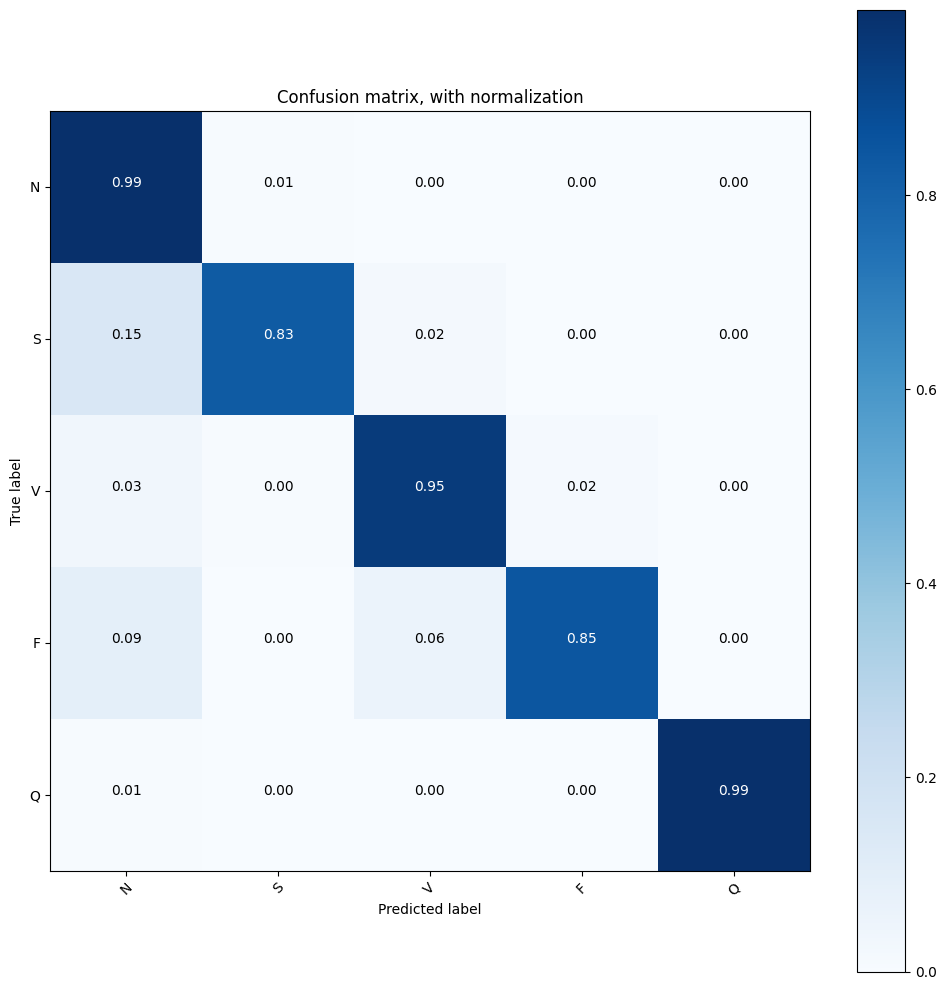

In [24]:
import itertools

from sklearn.metrics import confusion_matrix

import seaborn as sns
import matplotlib.pyplot as plt

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

# Compute confusion matrix
cnf_matrix = confusion_matrix(y_test, y_pred)
np.set_printoptions(precision=2)

# Plot non-normalized confusion matrix
plt.figure(figsize=(10, 10))
plot_confusion_matrix(cnf_matrix, classes=['N', 'S', 'V', 'F', 'Q'],normalize=True,
                      title='Confusion matrix, with normalization')
plt.show()